# Reduced attitude control: from trajectories to reconstructed graphs

Compare upright stabilization and coning through four steps: **physical flow → learned sphere → interval graph → sphere preimages and indices**.

Run all cells in order. The notebook regenerates physical data, loads all six saved checkpoints, recomputes CMGDB graphs and aggregate indices, and verifies the results against the frozen experiment. No training is performed. Full logs and editable figure exports are saved under `build/notebooks/attitude/`.

The learned model predicts the thrust axis on the invariant subsystem used for training. It does not reconstruct the full quadrotor state.

## 1. Locate the experiment

`Path` locates files, `json` reads the saved numerical report, NumPy handles arrays, and Matplotlib draws the figures directly in this notebook. `solve_ivp` integrates the explicitly defined scalar differential equations. The experiment source is the sibling `code/examples/example3/periodic` directory.

Before the first run, install the isolated replay environment from `code-kaito/`:
```bash
uv venv .venv-attitude --python 3.13
uv pip install --python .venv-attitude/bin/python -r ../code/requirements.txt
```
Use the usual notebook kernel. It launches the pinned replay interpreter separately. Graphviz and Poppler must be available as described in `code/README.md`.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "upstream.json").is_file())
EXPERIMENT = ROOT.parent / "code" / "examples" / "example3" / "periodic"
REPORT = EXPERIMENT / "reference" / "summary.json"
if not REPORT.is_file():
    raise FileNotFoundError("Clone the complete repository, including code/examples/example3/periodic/reference.")
rows = json.loads(REPORT.read_text())
assert {(r["policy"], r["seed"]) for r in rows} == {(p, s) for p in ("nominal", "coning") for s in range(3)}
OUT = ROOT / "build" / "notebooks" / "attitude"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Loaded saved reports for two controllers and three seeds each.")

Loaded saved reports for two controllers and three seeds each.


## 2. The physical subsystem

The plant state is (p,v,R,Ω) ∈ ℝ³ × ℝ³ ×  SO(3) × ℝ³. The observable Q:(p,v,R,Ω) ↦  Re₃ ∈  S² is the thrust axis, with e₃=(0,0,1). Write q=Q(p,v,R,Ω), z=q₃, and w=RΩ.

For a scalar gain a:[-1,1] → ℝ, the tangent vector field V_a:S² → ℝ³ is
$$V_a(q)=a(z)(e_3-zq)+\omega e_3\times q,\qquad \omega=\pi/\log2.$$
The desired angular velocity is w_d:S² → ℝ³, w_d(q)=q ×  V_a(q). With rate error η=w-w_d(q), the constructed moment feedback gives
$$\dot q=V_a(q)+\eta\times q,\qquad \dot\eta=-2\eta.$$
Thus η=0 is invariant. Training starts on this subsystem, where the flow F_t:S² →  S² closes on the thrust axis. Translation and heading can vary, but the learned decoder does not reconstruct them. This is not a model of arbitrary initial angular rates.

The physical quotient π:S² → [-1,1], π(q)=q₃, removes rotation about e₃. Its flow h_t:[-1,1] → [-1,1] solves
$$\dot z=a(z)(1-z^2).$$
Nominal control uses a(z)=1. Coning uses a(z)=1/4-z, giving an attracting latitude at z=1/4. For example, a coning trajectory at z=1/2 has ż=-3/16 and moves downward toward that latitude.

The next cell integrates these equations from several initial heights. Solid curves are trajectories. Dashed lines mark equilibria. Each figure is generated here and exported as PNG, PDF, and SVG.

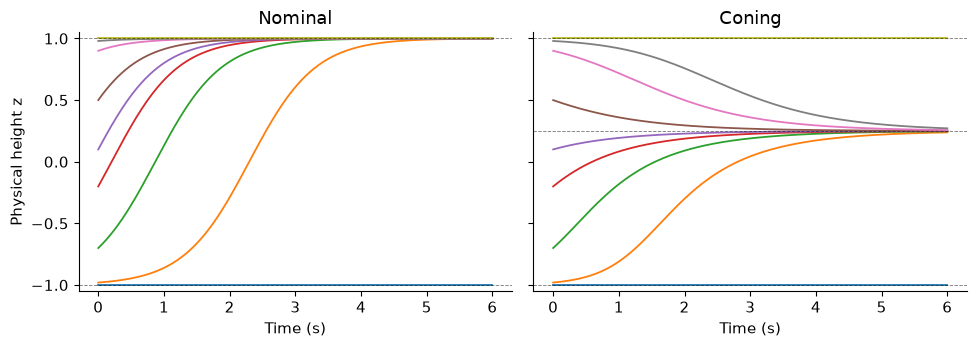

In [2]:
def height_rhs(t, z, policy):
    gain = np.ones_like(z) if policy == "nominal" else 0.25 - z
    return gain * (1 - z*z)

times = np.linspace(0, 6, 301)
starts = np.array([-1., -.98, -.7, -.2, .1, .5, .9, .98, 1.])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, policy in zip(axes, ("nominal", "coning")):
    sol = solve_ivp(lambda t, z: height_rhs(t, z, policy), (0, 6), starts,
                    t_eval=times, rtol=1e-10, atol=1e-12)
    assert sol.success and np.max(np.abs(sol.y)) <= 1 + 1e-9
    for curve in sol.y:
        ax.plot(times, curve, linewidth=1.3)
    equilibria = [-1, 1] if policy == "nominal" else [-1, .25, 1]
    assert np.allclose(height_rhs(0, np.array(equilibria), policy), 0)
    for z in equilibria:
        ax.axhline(z, color="black", linestyle="--", linewidth=.65, alpha=.5)
    ax.set(title=policy.capitalize(), xlabel="Time (s)", ylim=(-1.05, 1.05))
axes[0].set_ylabel("Physical height z")
fig.tight_layout()
for suffix in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"physical-height-trajectories.{suffix}", dpi=160, bbox_inches="tight")
plt.show()

## 3. What the networks learn

Let 𝒪 ⊂ ℝ¹⁸ denote the flattened full-plant observations. For an observation o, Q(o) extracts its three thrust-axis coordinates (entries 12–14 in Python indexing). The encoder E:𝒪 →  S² and axis decoder D:S² →  S² are normalized equivariant networks. Their raw vectors must be nonzero for these sphere-valued interpretations. Held-out checks support this, but global nonvanishing is not proved.

The loss includes ‖E(o)-Q(o)‖²: the known axis supervises the encoder. This is task-aware learning, not discovery of an unknown quotient from an unsupervised full-state reconstruction loss.

The learned sphere map f:S² →  S² combines scalar heads b,α:[-1,1] → ℝ. Its height map m:[-1,1] → [-1,1] is
$$m(z)=\frac{z\cosh b(z)+\sinh b(z)}{\cosh b(z)+z\sinh b(z)}.$$
The horizontal coordinates rotate by α(z) and divide by the same denominator. This preserves the sphere and fixes the poles. Interior fixed latitudes are learned through zeros of b.

A learned increasing piecewise-linear homeomorphism ψ:[-1,1] → [-1,1] defines π_Z:S² → [-1,1] by π_Z(q)=ψ(q₃). The quotient map is f̄=ψ ∘  m ∘ ψ⁻¹:[-1,1] → [-1,1]. Consequently, π_Z ∘  f=f̄ ∘ π_Z holds by construction, apart from numerical arithmetic. It is not an independently learned agreement.


## 4. Data and training configuration

Each controller uses 8,192 training, 2,048 validation, and 4,096 test trajectories. Each has 33 observations at 0.1-second spacing. The physical simulator uses normalized-quaternion RK4 with step 0.002 seconds. Initial states satisfy η=0, with a quarter of heights near the poles.

The sphere networks have width 64 and two hidden layers. Scalar heads have width 24, and ψ uses 33 knots. Training uses batches of 256, a 1,000-update calibration stage, and joint fitting through update 6,000. Prediction horizons are 1, 4, and 10 steps. The loss combines axis reconstruction, prediction, encoder calibration, physical closure, orbit reconstruction/prediction, and quotient consistency with weights (1,3,2,0.5,0.5,0.5,0.1).

Checkpoint and seed selection use the joint validation objective before graph computation. After replay, the table compares all six seeds rather than choosing the best test error.

## 5. Reproduce the saved experiment

The next cell calls the experiment's `replay` entry point. It verifies input checksums, regenerates the physical data, copies the saved weights into a fresh output directory, and runs forecast, native graph, aggregation, and independent audit checks. The numerical settings and validation-based selection are unchanged. Errors stop execution and point to the full log. Each Run All uses a fresh directory.

In [3]:
import os, sys, subprocess, tempfile
REPLAY_PYTHON = ROOT / ".venv-attitude" / "bin" / "python"
if not REPLAY_PYTHON.is_file():
    raise FileNotFoundError("Install .venv-attitude using the setup cell above.")
RUN = Path(tempfile.mkdtemp(prefix="replay-", dir=OUT))
REPLAY = RUN / "experiment"
log_path = RUN / "replay.log"
env = os.environ.copy()
env.update(MPLBACKEND="Agg", JAX_PLATFORM_NAME="cpu", MPLCONFIGDIR=str(OUT / "matplotlib"))
command = [str(REPLAY_PYTHON), str(EXPERIMENT.parent / "run.py"),
           "periodic", "replay", "--out", str(REPLAY)]
print("Replaying six saved fits. This includes data regeneration and graph checks.", flush=True)
with log_path.open("w") as log:
    result = subprocess.run(command, cwd=ROOT.parent / "code", env=env,
                            stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    raise RuntimeError(f"Replay failed. See {log_path}\n" + log_path.read_text()[-5000:])
TRAINED = REPLAY / "trained"
verification = json.loads((TRAINED / "replay-verification.json").read_text())
assert verification["passed"]
rows = json.loads((TRAINED / "summary.json").read_text())
print(f"Verified {len(verification['checks'])} fits against the frozen results. No retraining.")

Replaying six saved fits. This includes data regeneration and graph checks.


Verified 6 fits against the frozen results. No retraining.


In [4]:
selected = {}
lines = ["| Controller | Seed | Validation objective | One-second axis RMS | Native nodes |",
         "|---|---:|---:|---:|---:|"]
for policy in ("nominal", "coning"):
    candidates = [r for r in rows if r["policy"] == policy]
    selected[policy] = min(candidates, key=lambda r: (r["metrics"]["validation"]["objective"], r["seed"]))
    for r in sorted(candidates, key=lambda r: r["seed"]):
        metrics = r["metrics"]
        lines.append(f"| {policy} | {r['seed']} | {metrics['validation']['objective']:.6g} | "
                     f"{metrics['forecast_rms_by_horizon'][10]:.7f} | {len(r['graph']['nodes'])} |")
display(Markdown("\n".join(lines)))
print("Validation-selected seeds:", {p: r["seed"] for p, r in selected.items()})

| Controller | Seed | Validation objective | One-second axis RMS | Native nodes |
|---|---:|---:|---:|---:|
| nominal | 0 | 2.02909e-06 | 0.0010055 | 2 |
| nominal | 1 | 3.95741e-06 | 0.0014311 | 2 |
| nominal | 2 | 3.80298e-06 | 0.0012477 | 2 |
| coning | 0 | 7.18923e-06 | 0.0018308 | 4 |
| coning | 1 | 9.8252e-06 | 0.0020604 | 4 |
| coning | 2 | 9.32039e-06 | 0.0017331 | 4 |

Validation-selected seeds: {'nominal': 0, 'coning': 0}


The reported error is componentwise RMS of the decoded thrust axis, averaged over held-out trajectories and three coordinates. It is not a full-state reconstruction error. The following curves use the forecast errors recomputed in this replay.

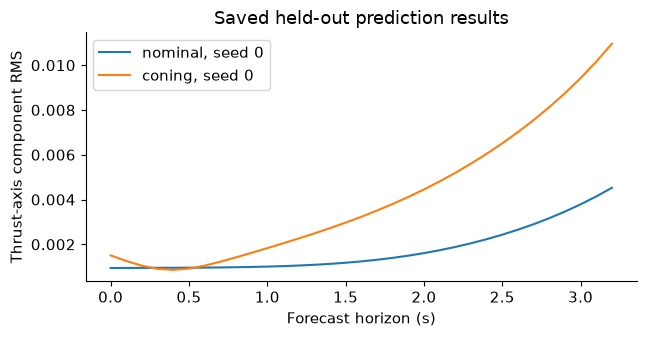

In [5]:
fig, ax = plt.subplots(figsize=(6.6, 3.5))
for policy, row in selected.items():
    errors = np.array(row["metrics"]["forecast_rms_by_horizon"])
    ax.plot(.1*np.arange(len(errors)), errors, label=f"{policy}, seed {row['seed']}")
ax.set(xlabel="Forecast horizon (s)", ylabel="Thrust-axis component RMS", title="Saved held-out prediction results")
ax.legend()
fig.tight_layout()
for suffix in ("png", "pdf", "svg"):
    fig.savefig(OUT / f"saved-axis-errors.{suffix}", dpi=160, bbox_inches="tight")
plt.show()

## 6. From interval cells to the reconstructed sphere graph

CMGDB analyzes f̄¹⁰ on 128 interval cells, corresponding to one second. Its callbacks sample 257 points per cell and pad the image hull by 2 × 10⁻⁶. These sampled hulls are not certified enclosures.

The nominal graph has two nodes. The coning graph has four native nodes, including a nearby trivial-index component. To obtain the three-node structural graph, the implementation merges the attracting component, the adjacent trivial-index component, and their connecting cells. It checks the merged index pair and recomputes its index. The matched physical reference in the learned coordinate also has four native nodes. This extra component must remain visible in the explanation.

Read the final presentation in this order: **computed interval graph → preimages on the sphere → reconstructed sphere indices**. A pole is a single point, whereas an interior height represents a circle. Thus quotient indices cannot simply be relabeled as sphere indices. In coning, the repelling poles have sphere homology in degree 2, and the attracting periodic circle has degrees 0 and 1. These original sphere indices have an analytical justification. Their identification with learned nodes is numerical.

## 7. Read the recomputed graphs and sphere preimages

The cell below draws every panel from this run's JSON and NPZ files. `graph_source` converts node annotations and directed edges into Graphviz geometry. For reconstructed panels, its `sphere_indices` rule inserts the analytically justified sphere indices by node role. This is an interpretation of the specified sphere model, not a fresh homology calculation on the full plant.

`sphere_panel` maps interval-cell membership back through the learned monotone coordinate and draws latitude bands. Pale fill denotes singleton-sink reachability in the finite graph. It is not a certified physical basin. The raw graph remains beside the aggregate so that the extra coning component is visible.

Each policy is shown in two rows: **native versus aggregate interval graphs**, followed by **sphere preimages versus reconstructed sphere indices**. Graphviz and Matplotlib generate PDF/SVG sources here. Poppler produces the portable PNG outputs.
Node labels N and S denote the north and south pole components, C denotes the attracting coning component, and A denotes the additional native component. Tuples list the index polynomials in increasing homological degree. Here x−1 represents an identity action on a one-dimensional homology group, and 0 denotes a trivial entry.


In [6]:
FIGURES = RUN / "figures"
FIGURES.mkdir()
render_script = """
from pathlib import Path
import json,sys,subprocess
import numpy as np
sys.path.insert(0,sys.argv[1])
from common.render_attitude import graph_source, sphere_panel
out=Path(sys.argv[2]); trained=Path(sys.argv[3])
selection=json.loads((trained/"selection.json").read_text())
for policy, chosen in selection.items():
    folder=trained/policy/f"seed{chosen['selected_seed']}"
    target=out/policy;target.mkdir(exist_ok=True)
    raw=json.loads((folder/"cmgdb/results.json").read_text())
    aggregate=json.loads((folder/"cmgdb/aggregate/results.json").read_text())
    assert aggregate["aggregation"]["index_pairs_checked"]
    for name,record,reconstructed in [("native",raw,False),("aggregate",aggregate,False),("reconstructed",aggregate,True)]:
        dot=graph_source(record,policy,reconstructed,1.)
        (target/f"{name}.dot").write_text(dot)
        for ext in ["pdf","svg"]:
            subprocess.run(["dot",f"-T{ext}","-o",str(target/f"{name}.{ext}")],input=dot,text=True,check=True)
    with np.load(folder/"cmgdb/aggregate/phase.npz") as saved:
        phase={k:saved[k] for k in saved.files}
    with np.load(folder/"diagnostics.npz") as saved:
        coordinate={"knots":saved["knots"],"values":saved["coordinate_values"]}
    sphere_panel(phase,coordinate,target/"preimages.pdf",True)
    for name in ["native","aggregate","preimages","reconstructed"]:
        subprocess.run(["pdftoppm","-scale-to","1100","-png","-singlefile",str(target/f"{name}.pdf"),str(target/name)],check=True,stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL)
"""
with (RUN / "figures.log").open("w") as log:
    result = subprocess.run([str(REPLAY_PYTHON), "-c", render_script,
                             str(EXPERIMENT.parents[1]), str(FIGURES), str(TRAINED)],
                            env=env, stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    raise RuntimeError((RUN / "figures.log").read_text()[-5000:])
print("Generated graphs and sphere preimages from the verified replay arrays.")

Generated graphs and sphere preimages from the verified replay arrays.


### Nominal control

The upright pole is the unique sink.

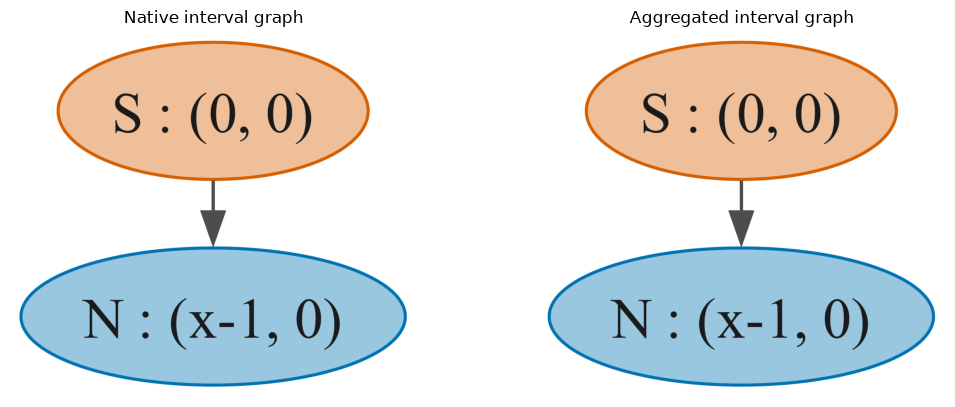

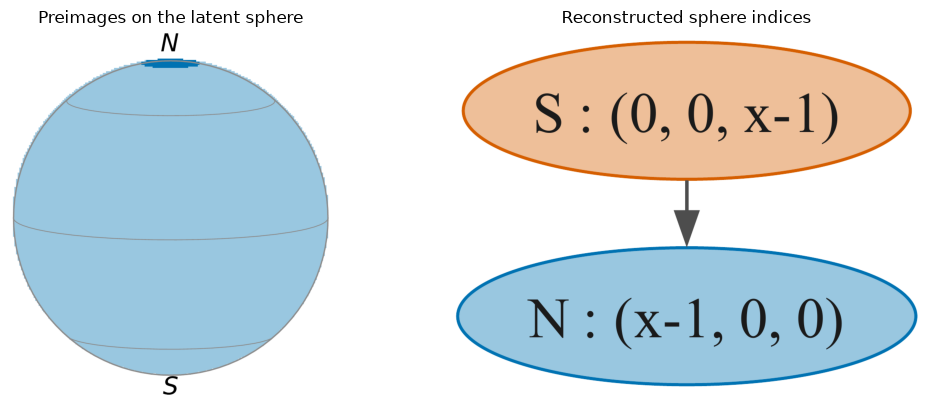

In [7]:
from PIL import Image as PILImage
policy = 'nominal'
for names, titles in [(('native', 'aggregate'), ('Native interval graph', 'Aggregated interval graph')),
                      (('preimages', 'reconstructed'), ('Preimages on the latent sphere', 'Reconstructed sphere indices'))]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, name, title in zip(axes, names, titles):
        ax.imshow(PILImage.open(FIGURES / policy / f"{name}.png"))
        ax.set_title(title, fontsize=12)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

### Coning control

The native graph includes an additional trivial-index component. The aggregate recomputes the index of its union with the attracting component and connecting cells.

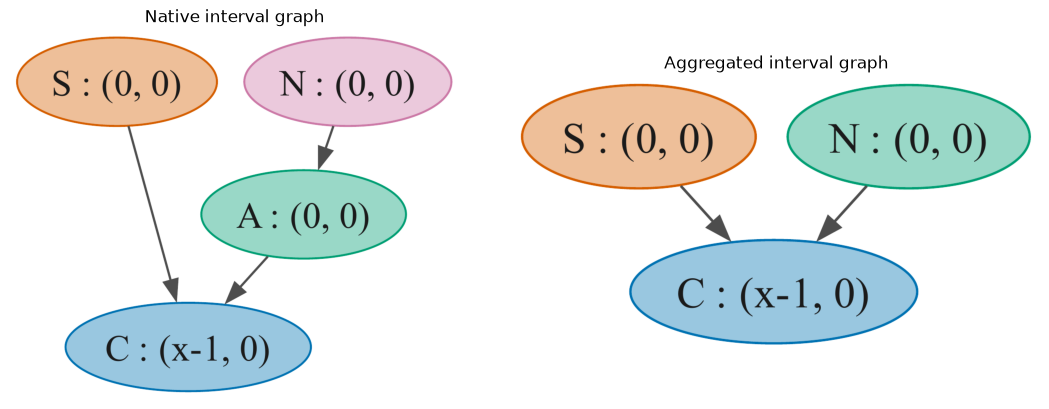

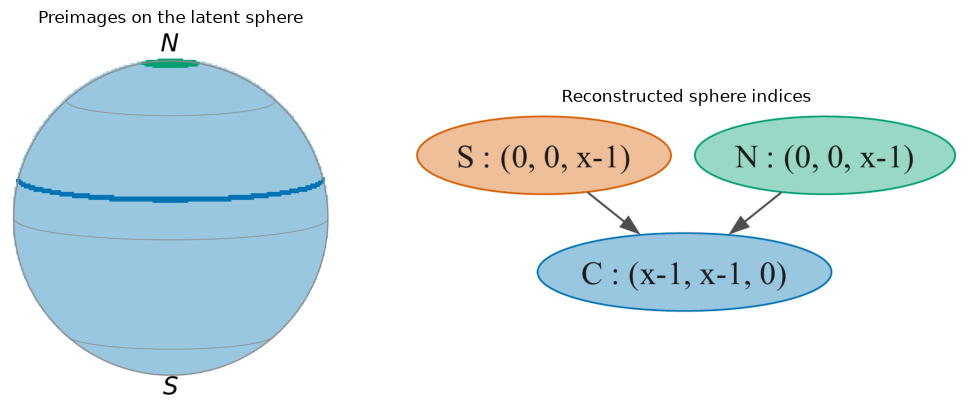

In [8]:
from PIL import Image as PILImage
policy = 'coning'
for names, titles in [(('native', 'aggregate'), ('Native interval graph', 'Aggregated interval graph')),
                      (('preimages', 'reconstructed'), ('Preimages on the latent sphere', 'Reconstructed sphere indices'))]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, name, title in zip(axes, names, titles):
        ax.imshow(PILImage.open(FIGURES / policy / f"{name}.png"))
        ax.set_title(title, fontsize=12)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 8. What the replay establishes

All six saved checkpoints reproduce the reported prediction errors and finite graphs. Validation selects seed 0 for both controllers. The figures connect the computed interval components to their latitude preimages and the sphere indices assigned by the analytical reconstruction.

These results concern the learned thrust-axis model trained on η=0. Sampled image hulls do not certify the full plant’s attracting regions, and reconstruction does not recover translation, heading, or arbitrary initial angular rates.